#***Explainable Credit Risk Assesment***
***Load the Data***

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


#***1. EDA***

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [ ]:
df.shape

(32581, 12)

***Missing Values from Columns***

In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


<Axes: xlabel='loan_status', ylabel='count'>

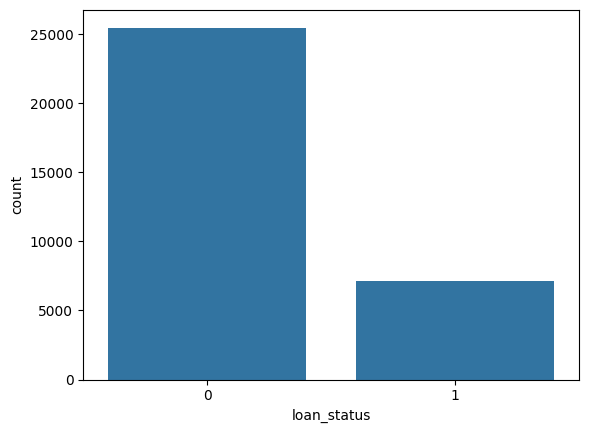

In [ ]:
df.head()
df['loan_status'].unique()
df['loan_status'].value_counts()

sns.countplot(x='loan_status', data = df)

***Outlier Check***

In [ ]:
(df['person_age']>100).sum()

np.int64(5)

In [ ]:
(df['person_emp_length']>100).sum()

np.int64(2)

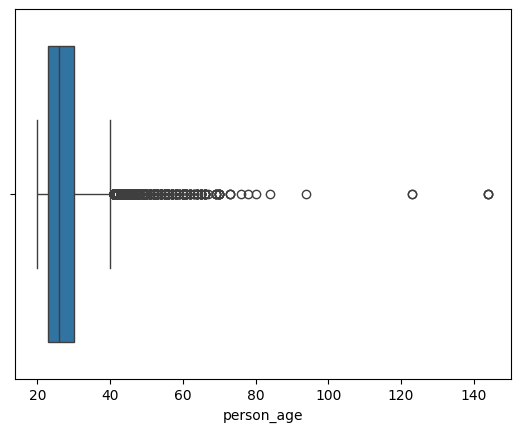

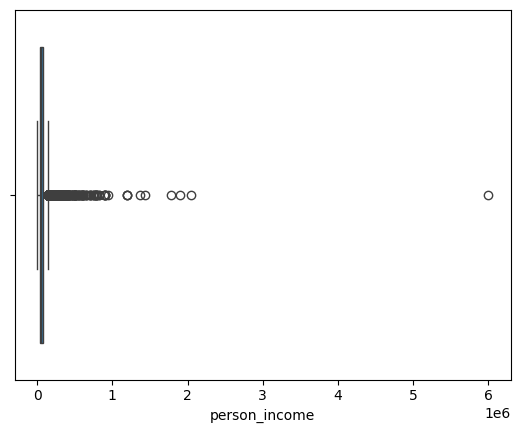

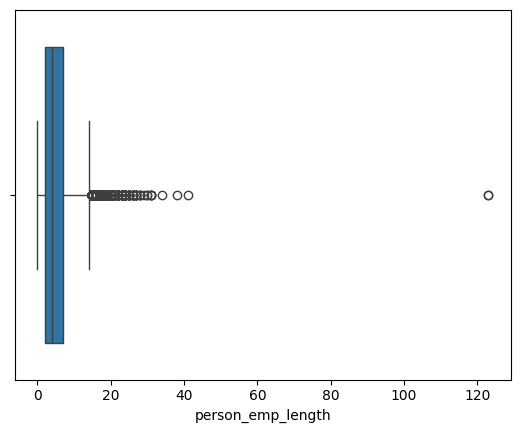

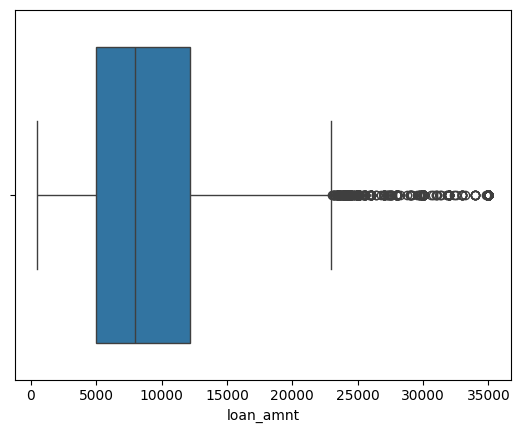

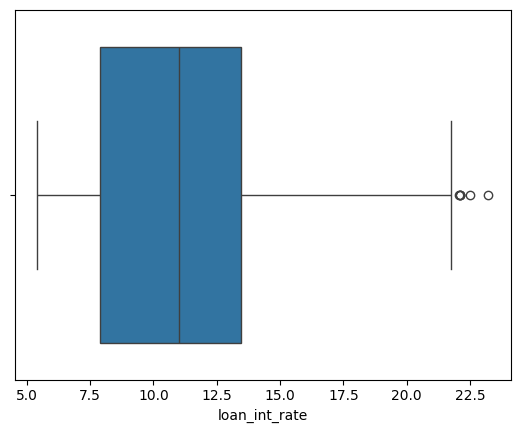

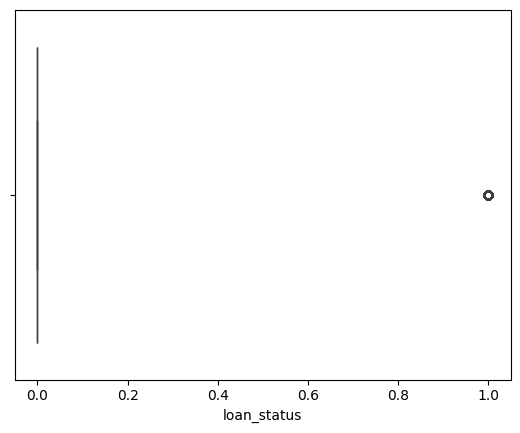

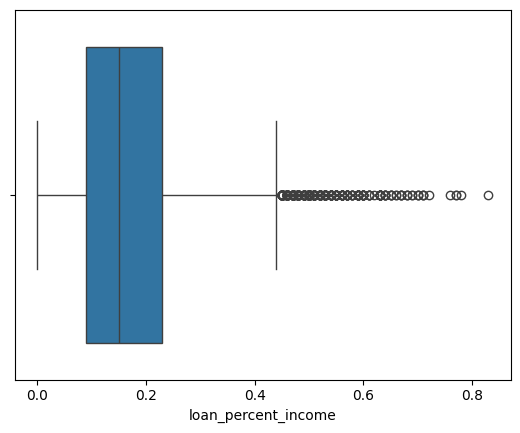

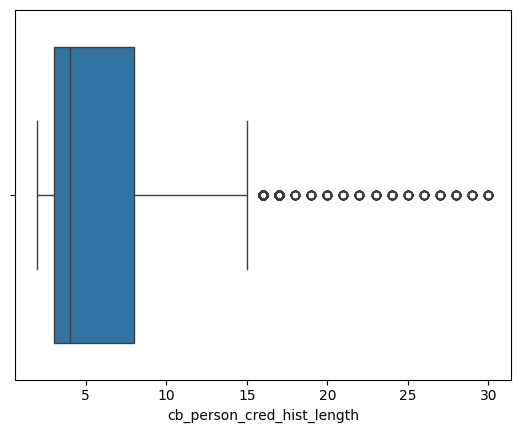

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns
numeric_cols
for i in numeric_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


***Correlation Check***

<Axes: >

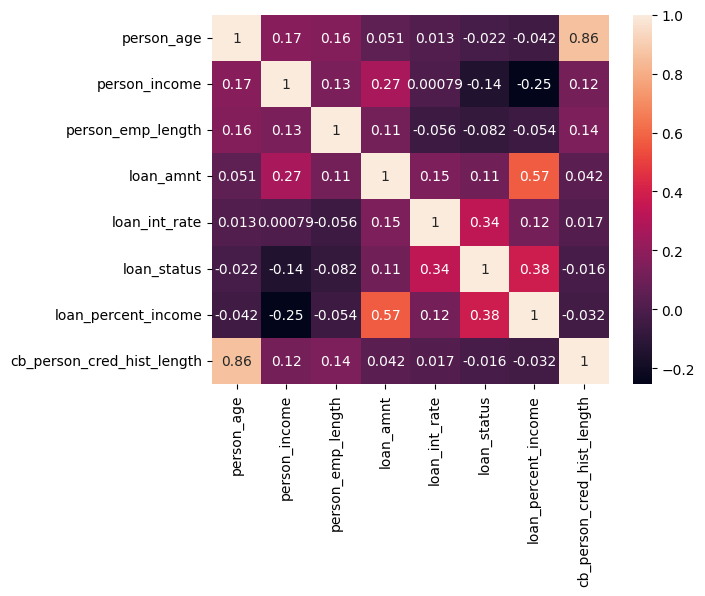

In [ ]:
sns.heatmap(df.corr(numeric_only = True), annot=True)

#***2. Data Validation & Outlier Handling***
* Here we clean the data properly.

* We remove duplicate rows.

* We remove rows with an impossible age or work experience.

* We remove rows with zero or negative income and loan amount.

* We check if the interest rate looks realistic.

* We also flag rows where numbers don't add up correctly.

In [ ]:
#REMOVE DUPLICATE ROWS
df_copy = df.copy()
print(f"original Rows : {df.shape[0]}")
df.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates: {df.shape[0]}")
df.shape

#REMOVE AGES BELOW 18 OR BELOW 100
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

#Remove employement length greater than age or extreme outliers(>60)
df_copy = df_copy[df_copy['person_emp_length']<=df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]

#Remove rows with zero or negative income and loan amount
df_copy=df_copy[df_copy['loan_amnt']>0]

#Check if the interest rate looks realistic.
print("Loan Interest rate range from (min: 5.42 and max: 23.22)")

original Rows : 32581
Rows after removing duplicates: 32416
Loan Interest rate range from (min: 5.42 and max: 23.22)


In [ ]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31679.000000,3.167900e+04,31679.000000,31679.000000,28632.000000,31679.000000,31679.000000,31679.000000
mean,27.730673,6.649010e+04,4.782064,9659.962436,11.039701,0.215442,0.169610,5.809211
std,6.213427,5.276879e+04,4.034948,6334.360554,3.229409,0.411135,0.106269,4.059710
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.936600e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


#***3. Features,Target & Train-Test Split***
* We separate the data into input features and the target.

* The target is whether the applicant defaulted or not.

* We split the data into a training part and a testing part.

* The model learns from the training part only.

In [ ]:
x= df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status']

from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

numeric_cols = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']

#***4. Handle Class Imbalance***
*Very few people actually default in this data.

* If we ignore this, the model may just favor the majority class.

* We give more importance to the minority class during training.

* This helps the model actually learn to spot defaulters.

In [ ]:
y_train.value_counts()

,count
loan_status,
0,19883
1,5460


In [ ]:
neg,pos = np.bincount(y_train)
scale_weight = neg/pos
scale_weight

np.float64(3.6415750915750915)

#***5. Data Preprocessig -- Pipelines & Columns Transfer***
*Raw data is not ready for a model directly.

* We need to prepare numeric and text columns differently.

* We will build a Pipeline for each model.

* We will use Column Transformer to apply different steps to different columns.

#***Preprocessing for Logistic Regression***

* Fill missing numeric values.

* Scale numeric values, since this model is sensitive to scale.

* Convert category columns into numbers using one-hot encoding.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


#Logistic Regration : impute + SCALE Numeric, impute + One-hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy = 'median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        #Pipeline - for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant",fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ])

#***6. Preprocessing for XGBoost***

* Fill missing numeric values.

* No scaling needed here, since tree models don't need it.

* Convert category columns into numbers using one-hot encoding.

In [ ]:
#XGBoost : impute numeric only, impute + One-hot-Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy = 'median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant",fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ])

#***7. Evaluation Helper Function***



* We build one common function to check any model's performance.

* It will show accuracy, precision, recall, F1 score, and more.

* It will also show a confusion matrix and a precision-recall curve.





In [ ]:
import numpy as np
#WE HAVE TO EVALUTE LOGISTIC MODEL AND XGBOOST MODEL ON THE BASIS OF THEIR MATRIXS

def evaluate_model(model_name,model,X_test,y_test,threshold=None):
  from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve
  import seaborn as sns
  import matplotlib.pyplot as plt

  y_pred = model.predict(X_test)
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold :
    y_pred = (y_pred_prob > threshold).astype(int)
    print(f"Threshold: {threshold:.2f}")
  else:
    y_pred = model.predict(X_test)
    print(f"Threshold: None")

  #Metrices
  accuracy = accuracy_score(y_test,y_pred)   #Overall model's Performance
  precision = precision_score(y_test,y_pred) #Of the ones I picked, how many were actually 1.
  recall = recall_score(y_test,y_pred)       # Of the actual 1 how many did the model catches
  f1 = f1_score(y_test,y_pred)               #Harmonic mean of precision and recall.

  #Confusion Matrix
  print(f"{model_name} Metrics")
  print(f"Accuracy: {accuracy:.2f}")
  print(f"Precision: {precision:.2f}")
  print(f"Recall: {recall:.2f}")
  print(f"F1: {f1:.2f}")
  print()

  #Classification Report
  print(f"{model_name} Classification Report")
  print(classification_report(y_test,y_pred))
  print()

  #Plotting Confusion Matrix
  cm = confusion_matrix(y_test, y_pred);
  plt.figure(figsize=(6,4))
  sns.heatmap(cm, annot=True, fmt='d')
  plt.title(f"{model_name} Confusion Matrix")
  plt.xlabel("Predicted Values")
  plt.ylabel("Actual Values")
  plt.show()

  #Plotting Precision-Recall curve
  precisions,recalls,thresholds = precision_recall_curve(y_test,y_pred_prob)
  plt.figure(figsize=(6,4))
  plt.plot(recalls,precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

#***8. Stratified Cross-Validation***

* One single train-test split may not be reliable.

* We split the training data into five folds instead.

* Each fold keeps the same default vs repaid ratio.

* We check the model's score across all folds.

In [ ]:
from sklearn.model_selection import StratifiedKFold,cross_validate
cv = StratifiedKFold(n_splits =5, shuffle = True, random_state =42)

scoring = {'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}

In [ ]:
#Logistic Regration
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight="balanced", random_state = 42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
#XGboost Model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators =  300, max_depth =  5, learning_rate = 0.1,scale_pos_weight = scale_weight, random_state=42, n_jobs=-1))
])

In [ ]:
from sklearn.model_selection import cross_validate

for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost",xgb_cv_pipeline)]:
                      print(cv_name, pipe)

                      cv_results=cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC AUC: {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
                      print(f"Precision: {cv_results['test_precision'].mean()}")
                      print(f"Recall: {cv_results['test_recall'].mean()}")
                      print(f"F1: {cv_results['test_f1'].mean()}")
                      print()

Logistic Regression Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                             

In [ ]:
cv_results

{'fit_time': array([2.63251305, 2.77833343, 2.67192245, 2.2544086 , 3.11755967]),
 'score_time': array([0.38290787, 0.28494644, 0.20687342, 0.22498274, 0.54938316]),
 'test_roc_auc': array([0.95725237, 0.94398538, 0.9467354 , 0.94494174, 0.94662526]),
 'test_accuracy': array([0.9252318 , 0.91457881, 0.91951075, 0.9187056 , 0.92205998]),
 'test_precision': array([0.83663834, 0.80312787, 0.82571429, 0.81775701, 0.84133203]),
 'test_recall': array([0.81135531, 0.79945055, 0.79395604, 0.80128205, 0.78663004]),
 'test_f1': array([0.82380288, 0.80128499, 0.80952381, 0.80943571, 0.813062  ])}

#***9. Baseline Model - Logistic Regression***

* We start with a simple model first.

* This becomes our benchmark to beat.

* We train it and check its score on the test data.

In [ ]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Threshold: None
Baseline Logistic Model Metrics
Accuracy: 0.81
Precision: 0.54
Recall: 0.79
F1: 0.64

Baseline Logistic Model Classification Report
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4971
           1       0.54      0.79      0.64      1365

    accuracy                           0.81      6336
   macro avg       0.74      0.80      0.76      6336
weighted avg       0.85      0.81      0.82      6336




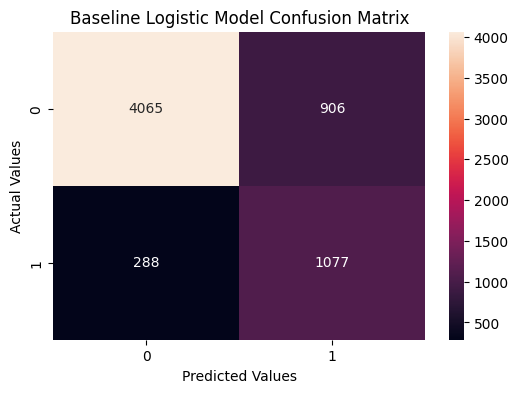

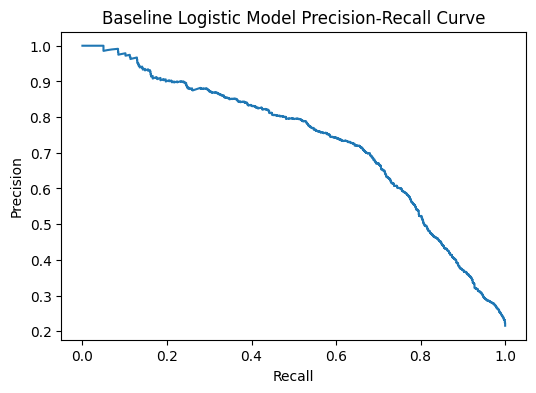

In [ ]:
# EVALUATE THE LOGISTIC MODEL

evaluate_model("Baseline Logistic Model", baseline_model,x_test,y_test)

#***10. XGBoost Hyperparameter Tuning***

* Now we move to a stronger model, XGBoost.

* A model has many settings called hyperparameters.

* We search for the best combination of these settings.

* We use cross-validation while searching, so the result is reliable.

In [ ]:
xg_model = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(learning_rate=0.1,scale_pos_weight=scale_weight,random_state=42))
])

xg_model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

Threshold: None
XGBoost Model Metrics
Accuracy: 0.92
Precision: 0.83
Recall: 0.79
F1: 0.81

XGBoost Model Classification Report
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      4971
           1       0.83      0.79      0.81      1365

    accuracy                           0.92      6336
   macro avg       0.89      0.87      0.88      6336
weighted avg       0.92      0.92      0.92      6336




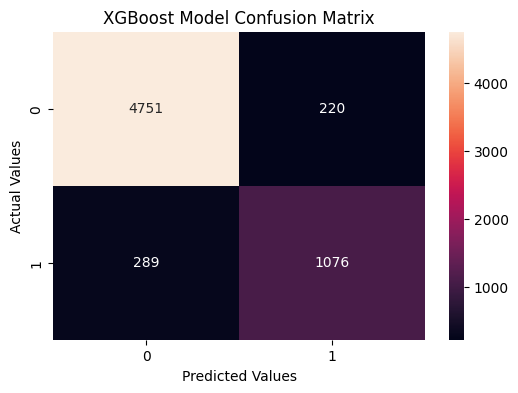

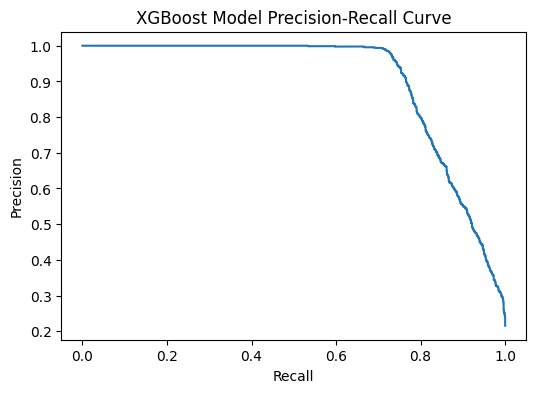

In [ ]:
# EVALUATE THE XGBOOST MODEL

evaluate_model("XGBoost Model", xg_model,x_test,y_test)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
import scipy.stats as stats

param_grid ={
    "classifier__n_estimators": stats.randint(150, 600),
    "classifier__max_depth": stats.randint(3, 9),
    "classifier__learning_rate": stats.uniform(0.01, 0.49), # From 0.01 to 0.01 + 0.49 = 0.5
    "classifier__subsample": stats.uniform(0.6, 0.4),           # Rows sampling from 0.6 to 1.1
    "classifier__colsample_bytree": stats.uniform(0.6, 0.4),    # Column sampling from 0.6 to 1.1
    "classifier__min_child_weight": stats.uniform(1, 9), # From 1 to 1 + 9 = 10
    "classifier__gamma": stats.uniform(0, 5)
}

#lower gamma ----> more splits ----> complex tree -----> higher overfiting risk
#higher gamma ----> less splits ----> simpler tree -----> low overfiting risk

In [ ]:
random_search = RandomizedSearchCV(
xg_model,
param_grid,
n_iter=150,
cv=cv,
scoring="average_precision",
n_jobs=-1,
verbose=1
)

random_search.fit(x_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b0cd9aa8890>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b0d1370aad0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b0cd9ac5f10>},
                   scoring='average_precision', verbose=1)

In [ ]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.6163468514751395),
 'classifier__gamma': np.float64(0.133872472605015),
 'classifier__learning_rate': np.float64(0.12347041068685156),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': np.float64(5.704724014809837),
 'classifier__n_estimators': 245,
 'classifier__subsample': np.float64(0.9042537139713275)}

In [ ]:
print(f"Score after performing tunning{random_search.best_score_:.2f}")

Score after performing tunning0.90


#***11. Compare Both Models Side by Side***

* We now compare Logistic Regression and XGBoost.

* We look at their scores together in one table.

* This helps us pick the better performing model.

Threshold: None
Logistic Regression Metrics
Accuracy: 0.81
Precision: 0.54
Recall: 0.79
F1: 0.64

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4971
           1       0.54      0.79      0.64      1365

    accuracy                           0.81      6336
   macro avg       0.74      0.80      0.76      6336
weighted avg       0.85      0.81      0.82      6336




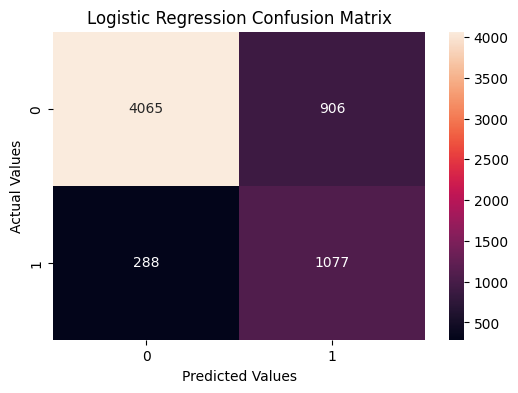

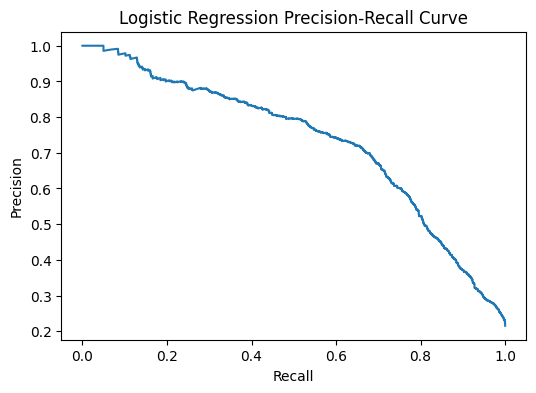

In [ ]:
#PASSING THE LOGISTIC MODEL AFTER PERFORMING HYPERPARAMETR TUNNING
evaluate_model("Logistic Regression", baseline_model,x_test,y_test)

Threshold: None
XGBoost Metrics
Accuracy: 0.92
Precision: 0.84
Recall: 0.80
F1: 0.82

XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4971
           1       0.84      0.80      0.82      1365

    accuracy                           0.92      6336
   macro avg       0.89      0.88      0.89      6336
weighted avg       0.92      0.92      0.92      6336




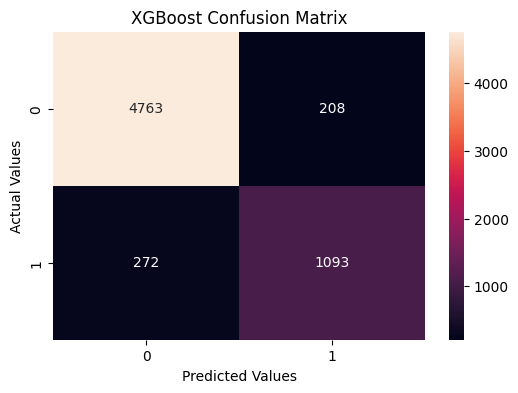

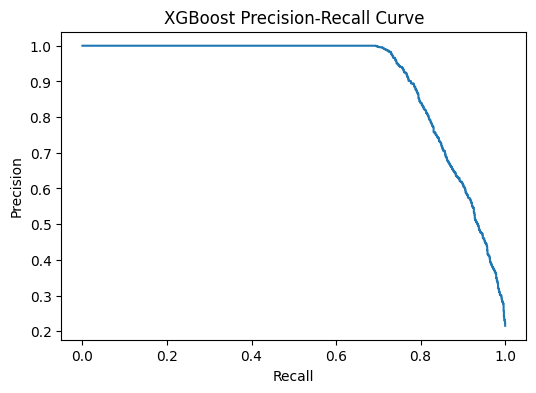

In [ ]:
#PASSING THE XGBOOST MODEL AFTER PERFORMING HYPERPARAMETR TUNNING
evaluate_model("XGBoost", random_search ,x_test,y_test)

#***12. Optimizing the Classification Threshold***

* The model gives a probability, not a direct yes or no.

* We decide a cut-off point to turn it into a decision.

* We check different cut-off points and pick the best one.

Threshold: 0.73
XGBoost Metrics
Accuracy: 0.94
Precision: 0.98
Recall: 0.73
F1: 0.84

XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4971
           1       0.98      0.73      0.84      1365

    accuracy                           0.94      6336
   macro avg       0.95      0.86      0.90      6336
weighted avg       0.94      0.94      0.93      6336




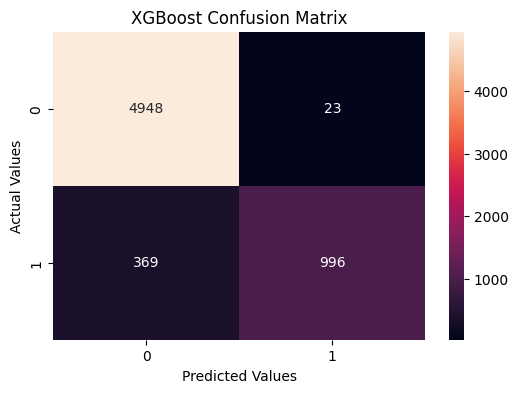

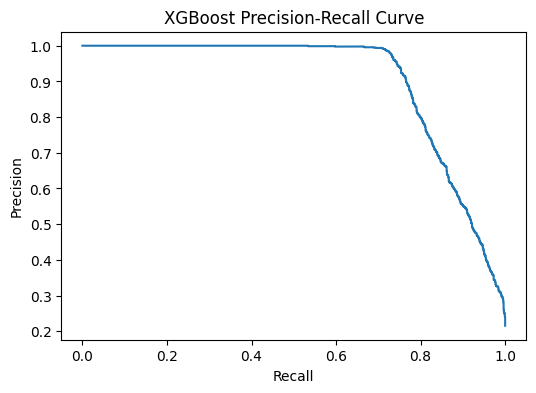

In [ ]:
from sklearn.metrics import precision_recall_curve

#Get the prob. of class 1 from XGBoost
prob = xg_model.predict_proba(x_test)[:,1]

#For each threshold calculate Precision and recall
precisions, recalls, thresholds = precision_recall_curve(y_test,prob)

#Calculate F1 score for each threshold (correct formula)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1_scores[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold
evaluate_model("XGBoost", xg_model ,x_test,y_test, best_threshold)

#***13. Probability Calibration***

* Sometimes a model's probability doesn't mean what it says.

* For example, 30% risk should truly mean a 30% chance.

* We check this with a calibration plot.

* We fix it if the probabilities are off.

In [ ]:
"""
methods by which we can fix the poorly calibrated model
1. platt scaling / sigmoid -> Adjust the probabilites using a sigmoid curve.
2.Isotonic Regration -> Learn a flexible mapping from old prob - better prob.(non-linear calibration)
3. Temperature Scaling -> Adjust the confidenceof neural-network predictions using one temperature scaling
"""

'\nmethods by which we can fix the poorly calibrated model\n1. platt scaling / sigmoid -> Adjust the probabilites using a sigmoid curve.\n2.Isotonic Regration -> Learn a flexible mapping from old prob - better prob.(non-linear calibration)\n3. Temperature Scaling -> Adjust the confidenceof neural-network predictions using one temperature scaling\n'

In [ ]:
#Calibrated XGBoost Model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
calibrated_model = CalibratedClassifierCV(
    xg_model,
    method = "sigmoid",
    cv=5
)
calibrated_model.fit(x_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                feature_weights=None,
                                                                gamma=None,
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=0.1,
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=None,
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=None,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [ ]:
#Calibrated Logistic Model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method = "sigmoid",
    cv=5
)
calibrated_model.fit(x_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.12347041068685156),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=np.float64(5.704724014809837),
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=245,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [ ]:
#Get Probabilities
uncalibrated = xg_model.predict_proba(x_test)[:,1]
calibrated = calibrated_model.predict_proba(x_test)[:,1]

uncalibrated
calibrated

array([0.01858023, 0.01328157, 0.01351868, ..., 0.01842956, 0.39476004,
       0.01452908])

In [ ]:
#create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins=10)
actual_cal, predicted_cal, = calibration_curve(y_test,calibrated,n_bins=10)

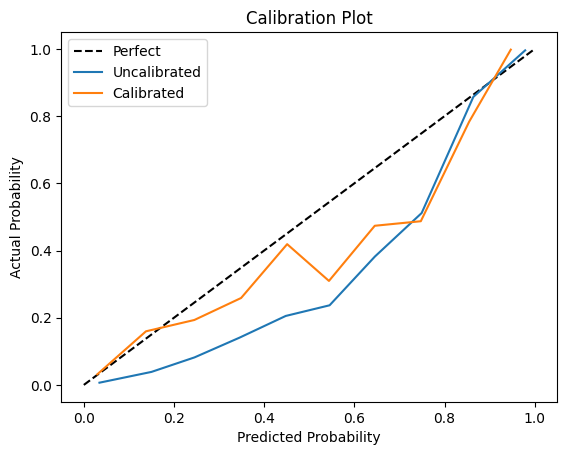

In [ ]:
#Plot
plt.plot([0,1],[0,1], 'k--', label = "Perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    label = "Uncalibrated"
)
plt.plot(
    predicted_cal,
    actual_cal,
    label = "Calibrated"
)
plt.xlabel("Predicted Probability")
plt.ylabel("Actual Probability")
plt.title("Calibration Plot")
plt.legend()
plt.show()


#***14. SHAP Interpretation - Global & Local***

* SHAP helps us understand why the model makes a decision.

* It is a way of explaining a "black box" model

In [ ]:
!pip install shap

In [ ]:
import shap

In [ ]:
#2. get the trained XGBoost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']

#3. Transform X_test using the same preprocessing used for training.
x_test_transformed = xg_model.named_steps['preprocessor'].transform(x_test)

#4. Get the feature names, after one hot encoding, so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

#5. convert to adataframe for clear SHAP plots
x_test_df = pd.DataFrame(x_test_transformed, columns = feature_names)
x_test_df

#6. Creat SHAP explainer built for tree_based model
explainer = shap.TreeExplainer(xgb_classifier)

#7. calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(x_test_df)
shap_values

array([[ 1.0441687e-02, -5.2936113e-01, -2.0260432e-01, ...,
        -1.1463670e-02, -1.3260413e-02,  0.0000000e+00],
       [-2.1444671e-03, -8.9884293e-01,  1.1811281e-01, ...,
        -9.4563337e-03, -2.7963495e-02,  0.0000000e+00],
       [ 1.0332015e-01, -5.4782414e-01, -1.4812831e-02, ...,
        -8.7608220e-03, -1.0818631e-02,  0.0000000e+00],
       ...,
       [ 8.6467326e-02, -1.1984890e+00, -2.5322162e-02, ...,
        -1.0622034e-02, -3.0617563e-02,  0.0000000e+00],
       [-2.1067753e-02,  7.2491944e-01,  4.6863709e-02, ...,
        -7.8593530e-03,  7.8139419e-04,  0.0000000e+00],
       [-7.6527894e-01, -9.0594453e-01,  7.3009029e-02, ...,
        -1.1260182e-02, -8.1929350e-03,  0.0000000e+00]], dtype=float32)

***Global explanation***

* This shows which features matter most overall.

* It also shows if a feature increases or decreases risk.

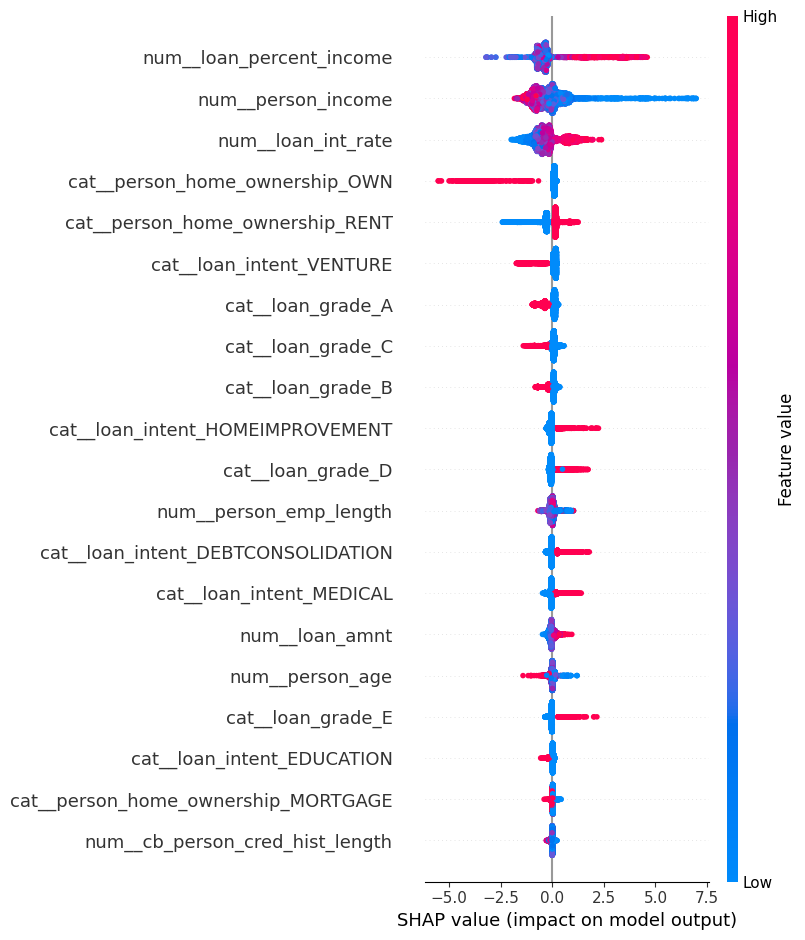

In [ ]:
shap.summary_plot(shap_values, x_test_df)

***Local explanation***
* This shows why one specific applicant got their score.
*  It breaks the score down feature by feature.

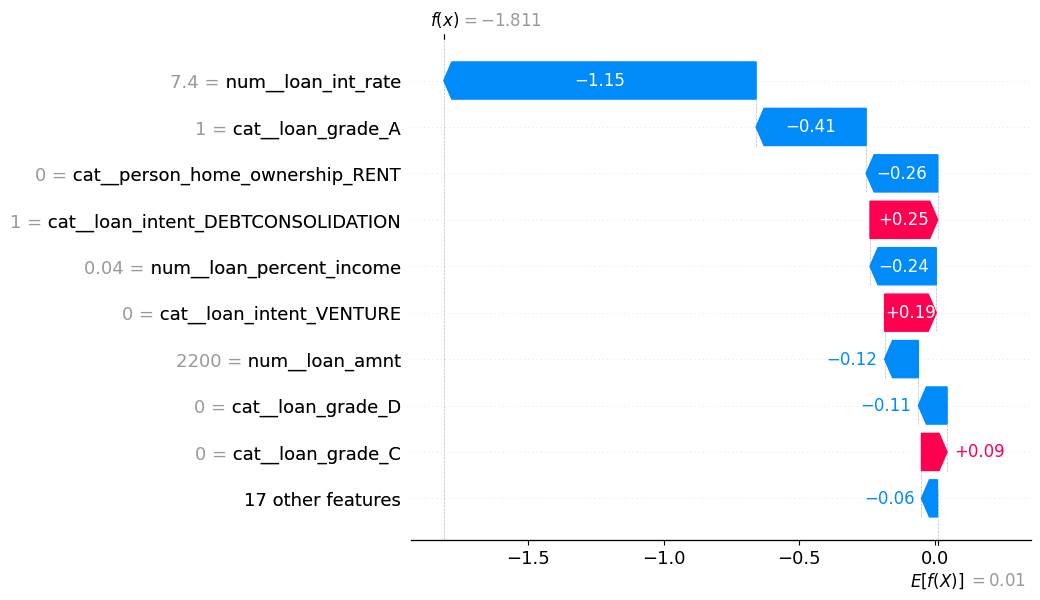

In [ ]:
#1.  Pick one row to explain, eg: the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = x_test_df.iloc[row_index],
        feature_names = x_test_df.columns
    )
)

#***15. Analyzing False Positives & False Negatives***

* The model will not be perfect.

* False positives are safe people wrongly marked risky.

* False negatives are risky people wrongly marked safe.

* We study these cases to understand where the model struggles.

In [ ]:
#Get prediction from the best performing XGBoost model on the test det
y_pred = random_search.predict(x_test)

# Create a dataframe to easily compare the actual and predicted values
result_df = x_test.copy()
result_df['Actual'] = y_test
result_df['Predicted'] = y_pred
result_df

# Identify False Poitive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['Actual']==0) & (result_df['Predicted']==1)]

# Identify False negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['Actual']==1) & (result_df['Predicted']==0)]

In [ ]:
print(f"False Positives: {len(false_positive)}")
print(f"False Negatives: {len(false_negative)}")

False Positives: 208
False Negatives: 272


In [ ]:
#False Negative > False Positive


#***16. Save the Final Model***

* Once we are happy with the model, we save it.

* We also save the settings it needs, like the chosen threshold.

* This saved file can now be used in a real application.

In [ ]:
import joblib

joblib.dump(calibrated_model,"credit_risk_model.pkl")
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

#1. Get probabilities from the CALIBRATED model, not the old xg_model
prob = calibrated_model.predict_proba(x_test)[:,1]

#2. Re-run the same threshold search, now on the correct probability scale
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)
f1_scores =2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold", best_threshold)

New threshold 0.6117830019171298
